# Grinder Detection Algorithm

Cross-correlation based approach for detecting coffee grinder sound.

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from pathlib import Path

## 1. Load Audio Files

In [2]:
# Load audio files
grinder_path = 'test_audio/grinder.wav'
background_path = 'test_audio/background-dishwasher.wav'

grinder_rate, grinder_audio = wavfile.read(str(grinder_path))
background_rate, background_audio = wavfile.read(str(background_path))

# Convert to float and normalize
grinder_audio = grinder_audio.astype(np.float32) / 32768.0
background_audio = background_audio.astype(np.float32) / 32768.0


/tmp/ipykernel_41918/3212212301.py:5: WavFileWarning: Chunk (non-data) not understood, skipping it.
  grinder_rate, grinder_audio = wavfile.read(str(grinder_path))


In [3]:
def detect_grinder_xcorr(audio, reference, frame_size=256, threshold=0.35, smooth_window=32):
    """
    Cross-correlation based grinder detector.

    Parameters:
    - audio: input audio signal to test
    - reference: grinder reference recording
    - frame_size: frame size in samples
    - threshold: detection threshold (0-1)
    - smooth_window: moving average window size

    Returns:
    - detections: boolean array of grinder detected per frame
    - energies: smoothed cross-correlation energies
    - raw_energies: raw cross-correlation energies before smoothing
    """

    # Normalize reference template to unit energy
    reference = reference / np.linalg.norm(reference) if np.linalg.norm(reference) > 0 else reference

    # Calculate number of frames
    n_frames = len(audio) // frame_size

    # Initialize energy array
    raw_energies = np.zeros(n_frames)
    energies = np.zeros(n_frames)

    alpha = 1 / smooth_window

    # Process each frame
    for i in range(n_frames):
        frame = audio[i*frame_size:(i+1)*frame_size]
        frame = frame / np.linalg.norm(frame) if np.linalg.norm(frame) > 0 else frame
        xcorr = np.correlate(frame, reference, mode='same')
        raw_energies[i] = np.max(np.abs(xcorr))
        energies[i] = alpha * raw_energies[i] + (1 - alpha) * energies[i-1] if i > 0 else raw_energies[i]

    # Threshold detection
    detections = energies > threshold

    return detections, energies, raw_energies

Average Smoothed Energy - Grinder: 0.4520, Background: 0.2436


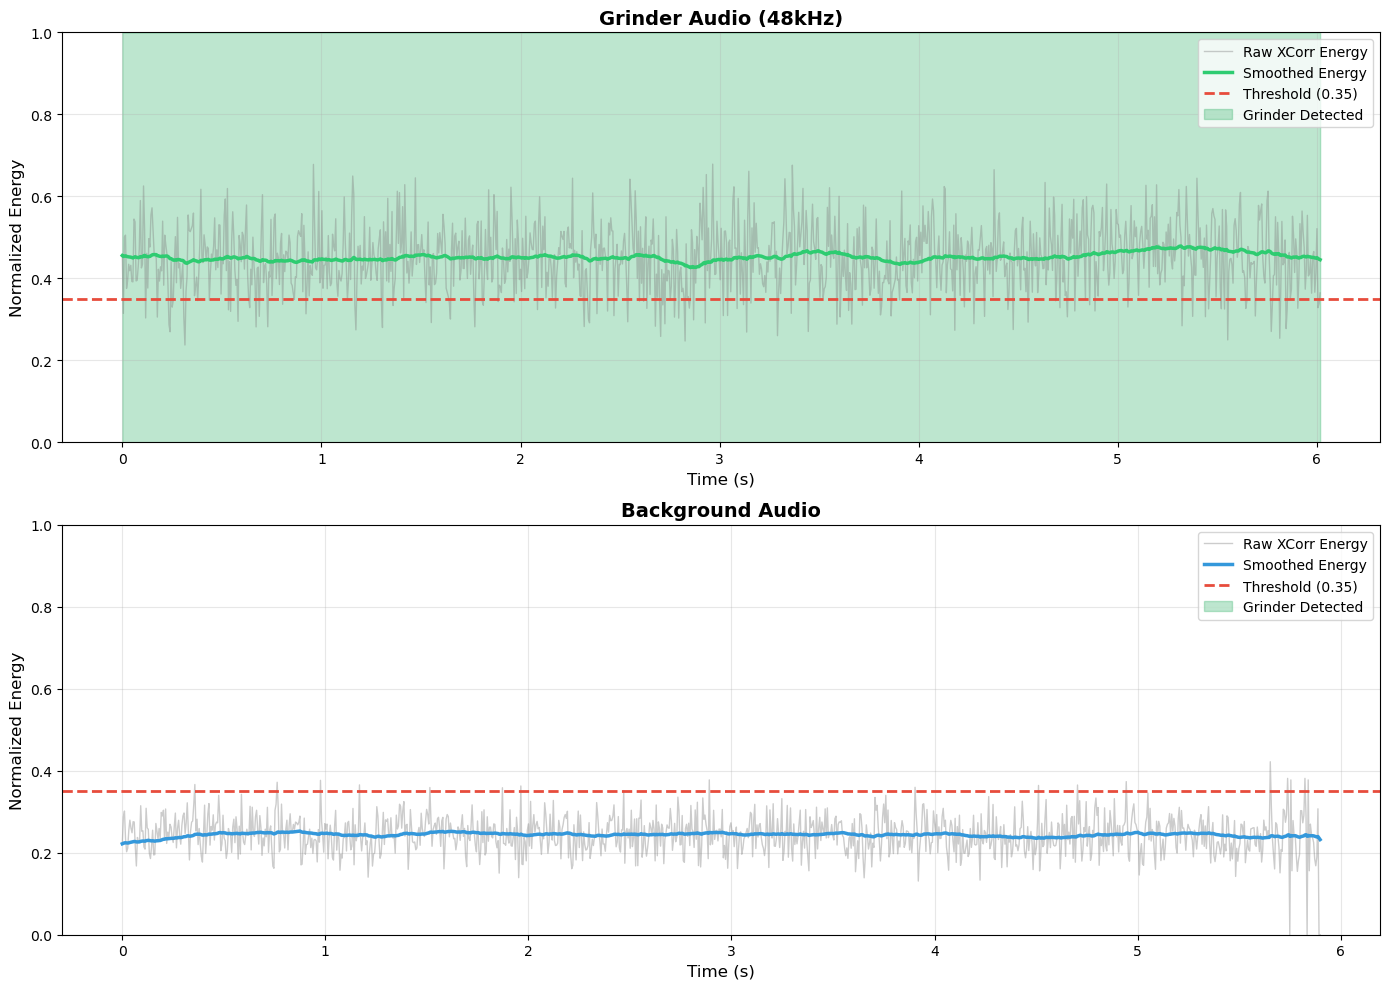

In [4]:
# Parameters for detection
frame_size = 256
threshold = 0.35
smooth_window = 64

# 
ref_start = len(grinder_audio) // 2 - frame_size // 2
ref = grinder_audio[ref_start:ref_start + frame_size]

# Run detection on both audio files
detections_grinder, energies_grinder, raw_grinder = detect_grinder_xcorr(
    grinder_audio,
    ref,
    frame_size=frame_size,
    threshold=threshold,
    smooth_window=smooth_window
)

detections_background, energies_background, raw_background = detect_grinder_xcorr(
    background_audio,
    ref,
    frame_size=frame_size,
    threshold=threshold,
    smooth_window=smooth_window
)

# Calculate and print average energies
avg_energy_grinder = np.mean(energies_grinder)
avg_energy_background = np.mean(energies_background)
print(f'Average Smoothed Energy - Grinder: {avg_energy_grinder:.4f}, Background: {avg_energy_background:.4f}')

# Plot results
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))

time_grinder = np.arange(len(energies_grinder)) * frame_size / grinder_rate
time_background = np.arange(len(energies_background)) * frame_size / background_rate

# Plot 1: Grinder test
ax1.plot(time_grinder, raw_grinder, 'gray', alpha=0.4, label='Raw XCorr Energy', linewidth=1)
ax1.plot(time_grinder, energies_grinder, '#2ecc71', linewidth=2.5, label='Smoothed Energy')
ax1.axhline(y=threshold, color='#e74c3c', linestyle='--', linewidth=2, label=f'Threshold ({threshold})')
ax1.fill_between(time_grinder, 0, 1, where=detections_grinder, alpha=0.3, color='#27ae60', label='Grinder Detected')
ax1.set_xlabel('Time (s)', fontsize=12)
ax1.set_ylabel('Normalized Energy', fontsize=12)
ax1.set_title('Grinder Audio (48kHz)', fontsize=14, fontweight='bold')
ax1.legend(fontsize=10, loc='upper right')
ax1.grid(True, alpha=0.3)
ax1.set_ylim(0, 1)

# Plot 2: Background test
ax2.plot(time_background, raw_background, 'gray', alpha=0.4, label='Raw XCorr Energy', linewidth=1)
ax2.plot(time_background, energies_background, '#3498db', linewidth=2.5, label='Smoothed Energy')
ax2.axhline(y=threshold, color='#e74c3c', linestyle='--', linewidth=2, label=f'Threshold ({threshold})')
ax2.fill_between(time_background, 0, 1, where=detections_background, alpha=0.3, color='#27ae60', label='Grinder Detected')
ax2.set_xlabel('Time (s)', fontsize=12)
ax2.set_ylabel('Normalized Energy', fontsize=12)
ax2.set_title('Background Audio', fontsize=14, fontweight='bold')
ax2.legend(fontsize=10, loc='upper right')
ax2.grid(True, alpha=0.3)
ax2.set_ylim(0, 1)

plt.tight_layout()

Average Smoothed Energy - Grinder: 0.4814, Background: 0.2739


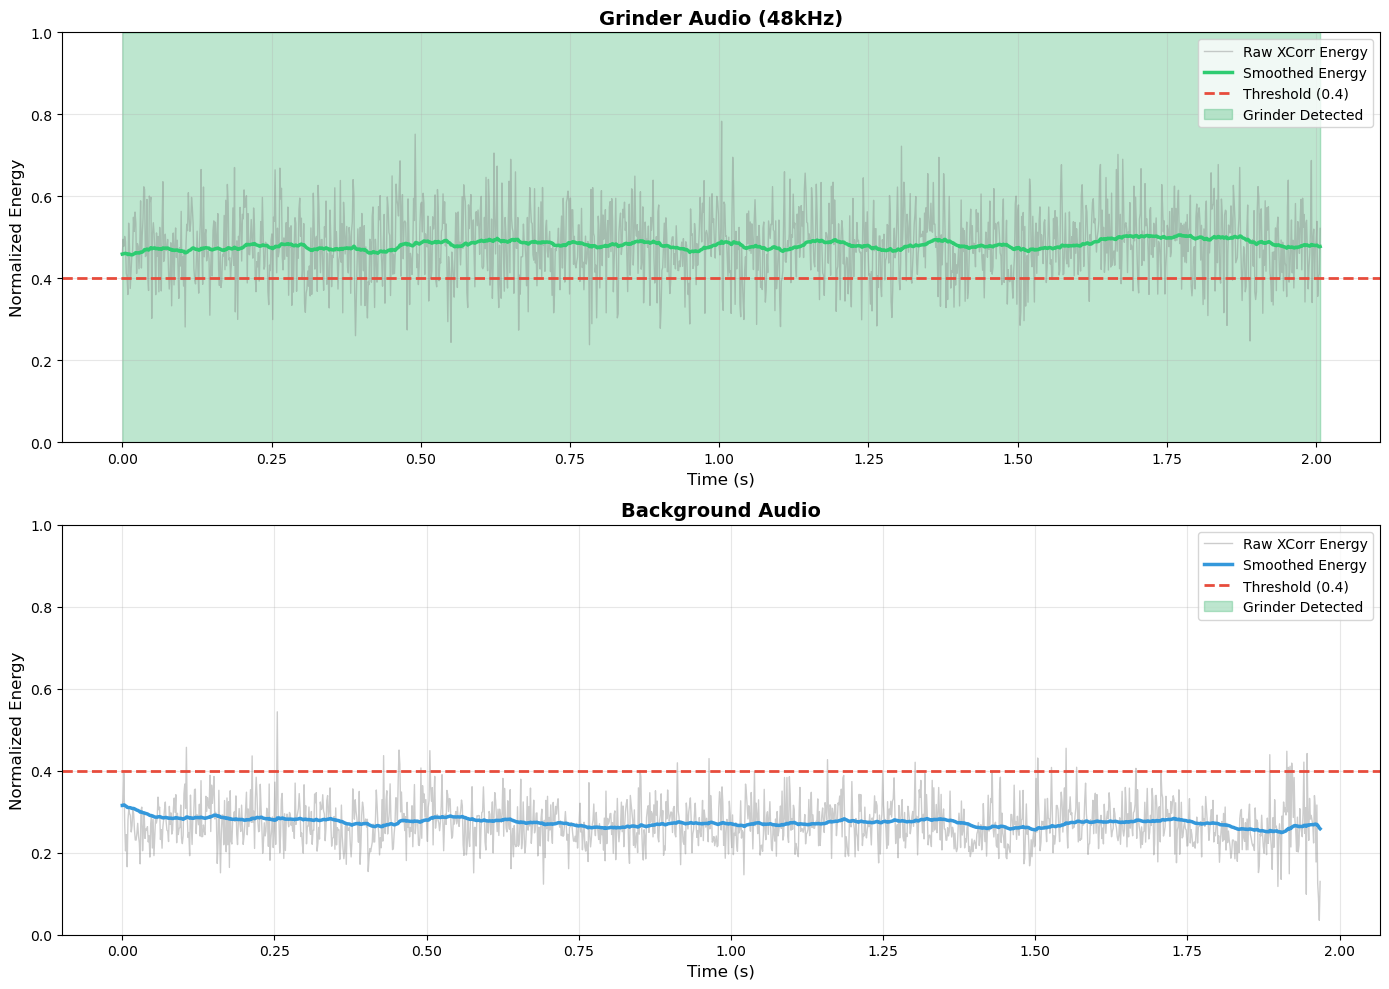

In [5]:
# Parameters for detection
frame_size = 64
threshold = 0.4
smooth_window = 64

# Downsample audio
target_rate = 16000
downsample_factor = grinder_rate // target_rate

grinder_ds = signal.decimate(grinder_audio, downsample_factor, ftype='iir')
background_ds = signal.decimate(background_audio, downsample_factor, ftype='iir')

# 
ref_start = len(grinder_ds) // 2 - frame_size // 2
ref = grinder_ds[ref_start:ref_start + frame_size]

# Run detection on both audio files
detections_grinder, energies_grinder, raw_grinder = detect_grinder_xcorr(
    grinder_ds,
    ref,
    frame_size=frame_size,
    threshold=threshold,
    smooth_window=smooth_window
)

detections_background, energies_background, raw_background = detect_grinder_xcorr(
    background_ds,
    ref,
    frame_size=frame_size,
    threshold=threshold,
    smooth_window=smooth_window
)

# Calculate and print average energies
avg_energy_grinder = np.mean(energies_grinder)
avg_energy_background = np.mean(energies_background)
print(f'Average Smoothed Energy - Grinder: {avg_energy_grinder:.4f}, Background: {avg_energy_background:.4f}')

# Plot results
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))

time_grinder = np.arange(len(energies_grinder)) * frame_size / grinder_rate
time_background = np.arange(len(energies_background)) * frame_size / background_rate

# Plot 1: Grinder test
ax1.plot(time_grinder, raw_grinder, 'gray', alpha=0.4, label='Raw XCorr Energy', linewidth=1)
ax1.plot(time_grinder, energies_grinder, '#2ecc71', linewidth=2.5, label='Smoothed Energy')
ax1.axhline(y=threshold, color='#e74c3c', linestyle='--', linewidth=2, label=f'Threshold ({threshold})')
ax1.fill_between(time_grinder, 0, 1, where=detections_grinder, alpha=0.3, color='#27ae60', label='Grinder Detected')
ax1.set_xlabel('Time (s)', fontsize=12)
ax1.set_ylabel('Normalized Energy', fontsize=12)
ax1.set_title('Grinder Audio (48kHz)', fontsize=14, fontweight='bold')
ax1.legend(fontsize=10, loc='upper right')
ax1.grid(True, alpha=0.3)
ax1.set_ylim(0, 1)

# Plot 2: Background test
ax2.plot(time_background, raw_background, 'gray', alpha=0.4, label='Raw XCorr Energy', linewidth=1)
ax2.plot(time_background, energies_background, '#3498db', linewidth=2.5, label='Smoothed Energy')
ax2.axhline(y=threshold, color='#e74c3c', linestyle='--', linewidth=2, label=f'Threshold ({threshold})')
ax2.fill_between(time_background, 0, 1, where=detections_background, alpha=0.3, color='#27ae60', label='Grinder Detected')
ax2.set_xlabel('Time (s)', fontsize=12)
ax2.set_ylabel('Normalized Energy', fontsize=12)
ax2.set_title('Background Audio', fontsize=14, fontweight='bold')
ax2.legend(fontsize=10, loc='upper right')
ax2.grid(True, alpha=0.3)
ax2.set_ylim(0, 1)

plt.tight_layout()